<a href="https://colab.research.google.com/github/AnastasiaaAlekseichuk/DCCAS_Alekseichuk/blob/main/%D0%9F%D0%A01_%D0%90%D0%BB%D0%B5%D0%BA%D1%81%D0%B5%D0%B9%D1%87%D1%83%D0%BA/pw_01_variant1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

**Дисциплина:** «Программные средства сбора, консолидации и аналитики данных»  
**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Программа:** «Бизнес-аналитика и большие данные»  
**Тема:** 1. Программные средства сбора данных  
**Формат:** интерактивный ноутбук Google Colab · **максимум 10 баллов** · срок сдачи — в Moodle (EnvLab)

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

1. Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.
2. Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.
3. Нормализовать «грязные» значения регулярными выражениями (числа, цены, остатки, даты; зарплаты и навыки — если они присутствуют в данных вашего варианта).
4. Подготовить таблицы `pandas` для API и HTML-данных, проверить качество, провести разведочный анализ и построить **не менее четырёх графиков** по варианту.
5. Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|---|---|
| Сбор | `requests` (+ `urllib3.Retry`), открытые REST API, кэш ответов на диске |
| Разбор HTML | `BeautifulSoup4` (CSS-селекторы), `lxml` (XPath) |
| Очистка | `re` — регулярные выражения |
| Анализ и графики | `pandas`, `numpy`, `matplotlib`, `seaborn` |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук **со всеми выводами ячеек**, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся **ссылка на репозиторий**. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

## Как работать с этим ноутбуком

1. **Файл → Сохранить копию на Диске.** Работайте только в своей копии.
2. В ячейке «Шаг 1» задайте **номер варианта** (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.
3. Выполняйте ячейки **строго сверху вниз**. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».
4. Места, которые нужно дописать, помечены `TODO`. Пока шаг не выполнен, ячейка честно падает с `NotImplementedError` — это нормально.
5. Перед сдачей запустите ячейку **самопроверки**. Она различает **✅ выполнено**, **❌ требует исправления**, **➖ не применяется** и **⚠ требует обоснования**. Число применимых проверок зависит от варианта; все применимые требования должны быть выполнены.
6. Если источник объективно предоставляет меньше 50 API-записей или 40 HTML-объектов, заполните пояснение непосредственно в ячейке самопроверки и в выводах. Самопроверка пометит этот пункт как требующий проверки преподавателем. Дублировать данные и подменять исходный вариант нельзя.
7. Номер варианта, показанный при первом открытии ноутбука, — **пример настройки**, а не назначение студенту. Выберите выданный преподавателем вариант.

### Три правила вежливого сбора данных

* **Пауза между запросами.** `REQUEST_PAUSE = 0.5` секунды — исходный учебный ориентир, не универсальное разрешение на такую частоту. Соблюдайте ограничения API, `Retry-After`, правила сайта и при необходимости увеличивайте паузу.
* **Кэш включён по умолчанию.** Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите `USE_CACHE` или очистите папку кэша.
* **Никаких ключей в коде.** Токены читаются функцией `get_secret()` из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. **Учебные или синтетические данные нельзя представлять как фактические рыночные результаты**; пометьте их источник и ограничения и повторите сбор, когда исходный ресурс станет доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

**API** — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

* **Эндпоинт** — «ручка» сервиса: `/vacancies`, `/works`, `/search/repositories`.
* **Параметры** уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
* **Заголовки** описывают клиента. `User-Agent` с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.
* **Коды ответа** — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать `r.json()` |
| 301 / 302 | адрес изменился | проверить итоговый `r.url` |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать `Retry-After`, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | `page`, `per_page` | GitHub, OpenAlex |
| Смещение и размер | `offset`, `limit` | «Работа в России» |
| Курсор | `cursor`, `next` | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем `per_page`, — данные закончились. Бесконечный `while True` без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

* пауза между запросами (`time.sleep`);
* повторные попытки с **экспоненциальной задержкой** — в работе это `urllib3.Retry(backoff_factor=1.5)`: 1,5 с → 3 с → 6 с;
* уважение заголовков `X-RateLimit-Remaining` и `Retry-After`;
* кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть **Secrets** (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через `userdata.get("MY_KEY")`. В работе это обёрнуто в `get_secret()`.

### Что изменилось к 2026 году (важно для выбора источника)

* **hh.ru**: с апреля 2026 публичный метод `GET /vacancies` отвечает `403 Forbidden` на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал **«Работа в России»** (`opendata.trudvsem.ru`), данные Роструда, ключ не нужен.
* **OpenAlex**: с 13 февраля 2026 всем запросам нужен бесплатный `api_key`, параметр `mailto` и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы `search` дороже, чем `filter`, а получение объекта по идентификатору бесплатно. Отсюда практический приём: `per-page=100` и фильтры вместо поиска.
* **GitHub**: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: **источник — это не константа**. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в **DOM** — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

| | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | `soup.select("article.product_pod p.price_color")` | `tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()')` |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | `el.get("title")` | `.../@title` |
| Текст | `el.get_text(" ", strip=True)` | `.../text()` |
| Поиск по тексту | `soup.find("th", string="UPC")` | `//th[text()="UPC"]` |
| Движение «вверх» и «вбок» | `el.parent`, `el.find_next_sibling()` | оси: `parent::`, `following-sibling::`, `ancestor::` |
| Условие по числу | средствами Python | `[position() <= 3]`, `[last()]` |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

**Когда что удобнее.** CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```python
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

1. **Цепляйтесь за смысл, а не за форму.** `div > div > div:nth-child(3)` сломается при первом же редизайне; `p.price_color` переживёт его.
2. **Проверяйте на нескольких страницах.** Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.
3. **Отсутствие элемента — норма.** `select_one()` вернёт `None`; парсер должен записать `None` в поле, а не падать.
4. **Сверяйте два способа.** В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.
5. **Динамические сайты.** Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от `"от 60 000 до 90 000 руб."` к паре `(60000, 90000)`.

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| `\d`, `\w`, `\s` | цифра, буква/цифра/подчёркивание, пробельный символ | `\d{4}` — год |
| `+`, `*`, `?`, `{n,m}` | повторения | `\d{1,3}` |
| `(?P<name>...)` | именованная группа | `(?P<min>\d+)` → `m.group("min")` |
| `(?:...)` | группировка без захвата | `(?:руб\.?|₽)` |
| `[...]`, `[^...]` | символьный класс и его отрицание | `[£$€₽]` |
| `\b` | граница слова | `\bBI\b` не совпадёт внутри `BigData` |
| `?` после квантификатора | ленивый режим | `<.+?>` |
| `re.I`, `re.S`, `re.X` | флаги: регистр, `.` включая перевод строки, «читаемый» режим | |

Функции: `re.search` — первое совпадение, `re.findall` — все, `re.sub` — замена, `re.compile` — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | `(?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?)` | в `1 250,50 ₽` стоит **неразрывный** пробел `\u00a0`, а десятичный разделитель — запятая |
| Остаток | `\((?P<n>\d+)\s*available\)` | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | `(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?` | «по договорённости» → `(None, None)`; одиночное число — это и нижняя, и верхняя граница |
| Дата | `(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})` и `\d{4}-\d{2}-\d{2}` | в одном источнике встречаются оба формата |
| Технология в тексте | `(?<![\w])(python|sql|power bi)(?![\w])` | без границ `bi` найдётся в «combined» |

### Чего делать не нужно

* **Разбирать HTML регулярками.** Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.
* **Писать одно «универсальное» выражение на все случаи.** Проще и надёжнее несколько маленьких функций с тестами.
* **Верить, что очистка прошла успешно.** Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

* **`robots.txt` и пользовательское соглашение.** Перед сбором смотрим `https://сайт/robots.txt` и раздел об использовании данных. Запрет в `robots.txt` — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.
* **Нагрузка.** Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.
* **Персональные данные.** Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.
* **Авторские права и лицензии.** Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.
* **Прозрачность.** В `User-Agent` указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны **учебные витрины** (`books.toscrape.com`, `quotes.toscrape.com`, `webscraper.io/test-sites`, `scrapethissite.com`), созданные специально для тренировки, и **открытые государственные и научные данные**. Навык переносится на коммерческие источники, а юридические риски — нет.

### Шаг 1. Окружение, параметры варианта и работа с ключами

**Зачем мы это делаем.** Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый `User-Agent` с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

* `Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))` — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
* `polite_get()` никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
* `get_secret()` ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [1]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 1               #@param {type:"slider", min:1, max:30, step:1}
CONTACT_EMAIL = "AlekseichkAA013@mgpu.ru"  #@param {type:"string"}
USE_CACHE = True          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()
CACHE_DIR = Path("/content/pw1_cache" if Path("/content").exists() else "pw1_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.

    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta

    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta

    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta

    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            data = r.json()
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        data = r.text
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.13.18 | requests 2.32.4 | bs4 4.13.5 | lxml 6.1.3 | pandas 2.2.3 | seaborn 0.13.2
Вариант: 1 | кэш: /content/pw1_cache | пауза между запросами: 0.5 с


**Как читать вывод.** В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Для публичных ресурсов ориентируйтесь на опубликованные ограничения и ответ сервера; при необходимости увеличьте паузу и обрабатывайте `429`/`Retry-After`.

In [2]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"area": "HR-аналитика",
"task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
"api": "trudvsem",
"api_params": {
"text": "инженер машинного обучения",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
},
{
"id": 2,
"area": "E-commerce",
"task": "Ценовое позиционирование в нише деловой литературы",
"api": "trudvsem",
"api_params": {
"text": "аналитик маркетплейсов",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
},
{
"id": 3,
"area": "Финтех",
"task": "Валютный риск закупок: динамика USD и EUR за квартал",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 90
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
},
{
"id": 4,
"area": "Мониторинг конкурентов",
"task": "Сравнение ассортимента двух товарных категорий",
"api": "github",
"api_params": {
"q": "price monitoring",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "fiction_10",
"pages": 4
},
"metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
},
{
"id": 5,
"area": "Наука и инновации",
"task": "Научная активность в сфере FinTech: динамика публикаций",
"api": "openalex",
"api_params": {
"search": "fintech",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "quotes",
"site_params": {
"tag": "inspirational",
"pages": 4
},
"metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
},
{
"id": 6,
"area": "Логистика",
"task": "Погодные риски на складских хабах: планирование окон отгрузки",
"api": "openmeteo",
"api_params": {
"cities": [
"Москва",
"Екатеринбург",
"Новосибирск"
],
"days": 14
},
"site": "books",
"site_params": {
"category": "history_32",
"pages": 2
},
"metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
},
{
"id": 7,
"area": "HR-аналитика",
"task": "Спрос на дата-инженеров и требования к стеку",
"api": "trudvsem",
"api_params": {
"text": "инженер данных",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
},
{
"id": 8,
"area": "E-commerce",
"task": "Влияние рейтинга на цену: есть ли премия за качество",
"api": "github",
"api_params": {
"q": "recommender system",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "romance_8",
"pages": 4
},
"metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
},
{
"id": 9,
"area": "Финтех",
"task": "Стоимость валютной корзины импортёра",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 120
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
},
{
"id": 10,
"area": "Мониторинг конкурентов",
"task": "Глубина ассортимента и «дыры» в наличии у конкурента",
"api": "trudvsem",
"api_params": {
"text": "категорийный менеджер",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "mystery_3",
"pages": 4
},
"metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
},
{
"id": 11,
"area": "Наука и инновации",
"task": "Публикационный ландшафт по теме «supply chain analytics»",
"api": "openalex",
"api_params": {
"search": "supply chain analytics",
"from_year": 2020,
"per_page": 100,
"pages": 2
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
},
{
"id": 12,
"area": "Логистика",
"task": "Температурный режим перевозок: risk-календарь на две недели",
"api": "openmeteo",
"api_params": {
"cities": [
"Санкт-Петербург",
"Казань",
"Краснодар"
],
"days": 14
},
"site": "webscraper",
"site_params": {
"section": "computers/tablets",
"pages": 3
},
"metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
},
{
"id": 13,
"area": "HR-аналитика",
"task": "BI-аналитики: сколько стоит и что требуют работодатели",
"api": "trudvsem",
"api_params": {
"text": "BI аналитик",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
},
{
"id": 14,
"area": "Технологические тренды",
"task": "Экосистема инструментов парсинга: кто лидирует",
"api": "github",
"api_params": {
"q": "web scraping",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "quotes",
"site_params": {
"tag": "books",
"pages": 3
},
"metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
},
{
"id": 15,
"area": "E-commerce",
"task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
"api": "trudvsem",
"api_params": {
"text": "менеджер интернет-магазина",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "childrens_11",
"pages": 4
},
"metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
},
{
"id": 16,
"area": "Финтех",
"task": "Курс юаня и импорт электроники: чувствительность цены",
"api": "cbr",
"api_params": {
"currencies": [
"CNY"
],
"days": 180
},
"site": "webscraper",
"site_params": {
"section": "phones/touch",
"pages": 2
},
"metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
},
{
"id": 17,
"area": "Наука и инновации",
"task": "Исследования по «digital twin» в промышленности",
"api": "openalex",
"api_params": {
"search": "digital twin manufacturing",
"from_year": 2018,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
},
{
"id": 18,
"area": "Мониторинг конкурентов",
"task": "Сравнение цен и «звёздности» ассортимента двух категорий",
"api": "github",
"api_params": {
"q": "e-commerce analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "food-and-drink_33",
"pages": 3
},
"metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
},
{
"id": 19,
"area": "HR-аналитика",
"task": "Логистические профессии: дефицит кадров по регионам",
"api": "trudvsem",
"api_params": {
"text": "логист",
"pages": 6,
"per_page": 100
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
},
{
"id": 20,
"area": "Логистика",
"task": "Окна доставки в северных хабах на горизонте 16 дней",
"api": "openmeteo",
"api_params": {
"cities": [
"Мурманск",
"Архангельск",
"Якутск"
],
"days": 16
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
},
{
"id": 21,
"area": "E-commerce",
"task": "Автоматизация мониторинга: как часто меняется наличие товара",
"api": "github",
"api_params": {
"q": "price tracker",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "sequential-art_5",
"pages": 4
},
"metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
},
{
"id": 22,
"area": "Финтех",
"task": "Волатильность рубля как фактор ценообразования",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 365
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
},
{
"id": 23,
"area": "HR-аналитика",
"task": "Продуктовые аналитики: требования и вилки",
"api": "trudvsem",
"api_params": {
"text": "продуктовый аналитик",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "humor",
"pages": 3
},
"metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
},
{
"id": 24,
"area": "Технологические тренды",
"task": "Инструменты работы с данными: Python-экосистема",
"api": "github",
"api_params": {
"q": "pandas alternative dataframe",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
},
{
"id": 25,
"area": "Наука и инновации",
"task": "Публикации по «marketplace pricing»: кто задаёт повестку",
"api": "openalex",
"api_params": {
"search": "marketplace pricing",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
},
{
"id": 26,
"area": "Логистика",
"task": "Планирование складских смен по погодным окнам",
"api": "openmeteo",
"api_params": {
"cities": [
"Ростов-на-Дону",
"Самара",
"Пермь"
],
"days": 14
},
"site": "scrapethissite",
"site_params": {
"section": "hockey",
"pages": 2
},
"metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
},
{
"id": 27,
"area": "Мониторинг конкурентов",
"task": "Бенчмарк цен на технику: разброс внутри линейки",
"api": "trudvsem",
"api_params": {
"text": "менеджер по закупкам",
"pages": 4,
"per_page": 100
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
},
{
"id": 28,
"area": "E-commerce",
"task": "Влияние глубины каталога на средний чек (гипотеза)",
"api": "github",
"api_params": {
"q": "shopping cart analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "poetry_23",
"pages": 4
},
"metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
},
{
"id": 29,
"area": "Финтех",
"task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 180
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
},
{
"id": 30,
"area": "E-commerce + HR (эталон преподавателя)",
"task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
"api": "trudvsem",
"api_params": {
"text": "аналитик данных",
"pages": 3,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
}
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}

def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))

Вариант 1 — HR-аналитика
Бизнес-задача: Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят

Источник API : opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)
Параметры API: {'text': 'инженер машинного обучения', 'pages': 5, 'per_page': 100}
Сайт парсинга: books.toscrape.com (учебная витрина интернет-магазина)
Параметры    : {'category': 'science_22', 'pages': 3}

Метрики и визуализации:
  Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой
  работой; гистограмма цен каталога


### Шаг 2. Сбор данных через открытый API

**Зачем мы это делаем.** API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

* остановка цикла, когда страница вернула меньше записей, чем запрошено;
* обращение к вложенным полям **только** через `.get()` — в открытых данных заполнены не все поля;
* печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

In [3]:
#@title Шаг 2. Сбор данных через открытый API (задание) { display-mode: "form" }
TRUDVSEM_URL = "http://opendata.trudvsem.ru/api/v1/vacancies"
CBR_DYNAMIC_URL = "https://www.cbr.ru/scripts/XML_dynamic.asp"
CBR_CODES = {"USD": "R01235", "EUR": "R01239", "CNY": "R01375", "GBP": "R01035", "JPY": "R01820"}
GITHUB_SEARCH_URL = "https://api.github.com/search/repositories"
OPENALEX_URL = "https://api.openalex.org/works"
OPENMETEO_URL = "https://api.open-meteo.com/v1/forecast"
CITY_COORDS = {
    "Москва": (55.75, 37.62), "Санкт-Петербург": (59.94, 30.31), "Екатеринбург": (56.84, 60.65),
    "Новосибирск": (55.03, 82.92), "Казань": (55.79, 49.11), "Краснодар": (45.04, 38.98),
    "Мурманск": (68.97, 33.08), "Архангельск": (64.54, 40.54), "Якутск": (62.03, 129.73),
    "Ростов-на-Дону": (47.23, 39.72), "Самара": (53.20, 50.15), "Пермь": (58.01, 56.25),
}
COLLECTED_AT = datetime.now(timezone.utc).astimezone().strftime("%Y-%m-%d %H:%M %Z")


# ------------------------------------------------------------------ TODO 2.1
def fetch_api(cfg):
    """Сбор вакансий «Работа в России» (вариант 1) с пагинацией offset/limit.

    * каждый запрос идёт через polite_get(): ретраи, пауза REQUEST_PAUSE, кэш;
    * offset — номер страницы (0, 1, 2, ...), limit — размер страницы;
    * цикл останавливается при ошибке, пустой странице, неполной странице
      или если страница не принесла ни одной новой вакансии (защита от зацикливания).
    """
    if cfg["api"] != "trudvsem":
        raise NotImplementedError("Реализован источник варианта 1 (trudvsem)")
    p = cfg["api_params"]
    per_page, max_pages = int(p.get("per_page", 100)), int(p.get("pages", 5))
    records, seen_ids = [], set()
    for page in range(max_pages):
        params = {"text": p["text"], "limit": per_page, "offset": page}
        data, meta = polite_get(TRUDVSEM_URL, params=params)
        if data is None:
            print(f"  страница {page}: ошибка — {meta['error']}; сбор остановлен")
            break
        batch = ((data.get("results") or {}).get("vacancies")) or []
        new = []
        for item in batch:
            vac = (item or {}).get("vacancy") or {}
            vid = vac.get("id")
            if vid and vid not in seen_ids:          # дубликаты между страницами не берём
                seen_ids.add(vid)
                new.append(vac)
        records.extend(new)
        total = (data.get("meta") or {}).get("total")
        src = "из кэша" if meta.get("from_cache") else f"HTTP {meta.get('status')}"
        print(f"  страница {page}: получено {len(batch)}, новых {len(new)} "
              f"(всего в источнике: {total}; {src})")
        if not batch or not new or len(batch) < per_page:
            print("  данные исчерпаны — остановка пагинации")
            break
    print(f"Итого уникальных вакансий: {len(records)} | дата сбора: {COLLECTED_AT}")
    return records


# ------------------------------------------------------------------ TODO 2.2
def _first(*values):
    """Первое непустое значение из списка кандидатов."""
    for v in values:
        if v not in (None, "", [], {}):
            return v
    return None


def normalize_api(raw, source):
    """Плоская таблица вакансий: все вложенные поля — через .get()."""
    rows = []
    for v in raw or []:
        region = v.get("region") or {}
        company = v.get("company") or {}
        req = v.get("requirement") or {}
        category = v.get("category") or {}
        rows.append({
            "id": v.get("id"),
            "title": v.get("job-name"),
            "region": region.get("name"),
            "region_code": region.get("region_code"),
            "employer": _first(company.get("name"), company.get("company_name")),
            "salary_min_raw": v.get("salary_min"),
            "salary_max_raw": v.get("salary_max"),
            "salary_text": v.get("salary"),
            "currency": v.get("currency"),
            "employment": v.get("employment"),
            "schedule": v.get("schedule"),
            "experience": req.get("experience"),
            "education": req.get("education"),
            "requirements_text": " ".join(str(x) for x in
                                          (req.get("qualification"), v.get("duty")) if x),
            "specialisation": category.get("specialisation"),
            "created_text": v.get("creation-date"),
            "url": v.get("vac_url"),
        })
    return rows


raw_api = fetch_api(CFG)
print("Ключи первой записи:", sorted(raw_api[0].keys()) if raw_api else "нет данных")
df_api = pd.DataFrame(normalize_api(raw_api, CFG["api"]))
API_SOURCE = CFG["api"]
if df_api.empty:
    print("⚠ API не вернул данных: проверьте доступность opendata.trudvsem.ru и журнал REQUEST_LOG")
print(f"Собрано записей: {len(df_api)}")
display(df_api.head())


  страница 0: получено 13, новых 13 (всего в источнике: 13; HTTP 200)
  данные исчерпаны — остановка пагинации
Итого уникальных вакансий: 13 | дата сбора: 2026-11-09 16:44 UTC
Ключи первой записи: ['addresses', 'category', 'code_profession', 'company', 'contact_list', 'contact_person', 'creation-date', 'currency', 'date_modify', 'duty', 'employment', 'id', 'job-name', 'qualification', 'region', 'requirement', 'requirements', 'salary', 'salary_max', 'salary_min', 'schedule', 'shift', 'skills', 'social_protected', 'source', 'trainingDays', 'typicalPosition', 'vac_url', 'workPlaceType', 'work_places']
Собрано записей: 13


,id,title,region,region_code,employer,salary_min_raw,salary_max_raw,salary_text,currency,employment,schedule,experience,education,requirements_text,specialisation,created_text,url
0,0ed70a47-c724-11f1-aa68-7523fb122f6d,Ведущий инженер по машинному обучению,Самарская область,6300000000000,"ООО ""ФИНТЕХ-МАРКЕТ""",197300,296000,от 197300,«руб.»,Дистанционная (удаленная) работа,Полный рабочий день,6,Высшее образование — бакалавриат,По данной вакансии просим звонить по номеру: 8...,"Информационные технологии, телекоммуникации, с...",2026-10-13,https://trudvsem.ru/vacancy/card/1236300023849...
1,d913f79f-a83a-11f1-b4b9-312b1e80675a,Инженер машинного обучения,Город Санкт-Петербург,7800000000000,"ООО ""ПЕТРОВИЧ-ТЕХ""",228500,285700,от 228500,«руб.»,Дистанционная (удаленная) работа,Неполный рабочий день/неполная рабочая неделя,6,"Высшее образование — специалитет, магистратура",участвовать в полном цикле DS/ML-проектов: от ...,"Информационные технологии, телекоммуникации, с...",2026-09-04,https://trudvsem.ru/vacancy/card/1227800065173...
2,05092614-cd41-11f1-acc4-3f3a02315f4e,Ведущий инженер по машинному обучению [Секрета...,Город Москва,7700000000000,МТС,30000,0,от 30000,«руб.»,None,Полный рабочий день,0,Не указано,"Секретарь - умный робот, умеющий вести констру...","Информационные технологии, телекоммуникации, с...",2026-10-21,https://trudvsem.ru/vacancy/card/7226c750-02f1...
3,93cbd4ca-d90c-11f1-a436-1770a8f10f28,Главный механик (в прочих отраслях),Ставропольский край,2600000000000,ИПАТОВСКИЙ ФИЛИАЛ ГОСУДАРСТВЕННОГО БЮДЖЕТНОГО ...,43000,60000,от 43000,«руб.»,Временная работа,Полный рабочий день,1,Среднее профессиональное образование,"Производит выпуск автомобилей, дорожно-строите...","Строительство, ремонт, стройматериалы, недвижи...",2026-11-05,https://trudvsem.ru/vacancy/card/623e05e0-8c47...
4,df604f1b-f5d7-11f0-8628-a3cca5294b78,Ведущий инженер по радиоэлектронике,Город Москва,7700000000000,"АО ""КОРПОРАЦИЯ ""ФАЗОТРОН-НИИР""",105000,105000,от 105000,«руб.»,Полная занятость,Полный рабочий день,2,Высшее образование — бакалавриат,"выполнение расчетов, разработка и практическая...",Производство,2026-01-20,https://trudvsem.ru/vacancy/card/1027700069902...


**Как читать вывод.** Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак `из кэша`: при повторном запуске сеть не используется, поэтому для свежих данных выключайте `USE_CACHE`.

Если используется аварийный, офлайн- или синтетический набор данных, явно обозначьте это в ноутбуке. Такой набор подходит для отладки, но не подтверждает выводы о состоянии реального рынка.

### Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

**Зачем мы это делаем.** Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это **контроль качества**: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию `SITES`: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

In [4]:
#@title Шаг 3. Парсинг HTML: BeautifulSoup и XPath (задание) { display-mode: "form" }
# Конфигурации сайтов даны частично: селекторы своего сайта проверьте сами
# (в браузере: правый клик по элементу → «Просмотреть код»).
from urllib.parse import urljoin

SITES = {
    "books": {
        "page_url": lambda p, category=None, **kw: (
            f"https://books.toscrape.com/catalogue/category/books/{category}/"
            + ("index.html" if p == 1 else f"page-{p}.html")),
        "item_css": "article.product_pod",
        "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"),
                       "availability_text": ("p.instock.availability", "text"),
                       "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")},
        "item_xpath": '//article[contains(@class, "product_pod")]',
        "fields_xpath": {"title": './/h3/a/@title', "price_text": './/p[@class="price_color"]/text()',
                         "availability_text": './/p[contains(@class, "instock")]//text()',
                         "rating_class": './/p[contains(@class, "star-rating")]/@class',
                         "url": './/h3/a/@href'},
    },
    "quotes": {
        "page_url": lambda p, tag=None, **kw: (
            f"https://quotes.toscrape.com/tag/{tag}/page/{p}/" if tag
            else f"https://quotes.toscrape.com/page/{p}/"),
        "item_css": "div.quote",
        "fields_css": {"text": ("span.text", "text"), "author": ("small.author", "text"),
                       "tags": ("div.tags", "text"), "url": ("span a", "href")},
        "item_xpath": '//div[@class="quote"]',
        "fields_xpath": {"text": './/span[@class="text"]/text()',
                         "author": './/small[@class="author"]/text()',
                         "tags": './/div[@class="tags"]//a[@class="tag"]/text()',
                         "url": './/span/a/@href'},
    },
}
MAX_DETAIL_PAGES = 60   # верхняя граница запросов к карточкам товаров (вежливость)


def fix_mojibake(text):
    """books.toscrape не указывает charset в заголовке, requests декодирует UTF-8 как latin-1
    ('Â£51.77'). Возвращаем корректный UTF-8, если перекодировка возможна."""
    try:
        return text.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text


# ------------------------------------------------------------------ TODO 3.1
def parse_with_bs4(html, site):
    """CSS-селекторы BeautifulSoup: карточка → словарь полей; нет элемента → None."""
    conf = SITES[site]
    soup = BeautifulSoup(html, "lxml")
    rows = []
    for card in soup.select(conf["item_css"]):
        row = {}
        for field, (selector, attr) in conf["fields_css"].items():
            el = card.select_one(selector)
            if el is None:
                row[field] = None
            elif attr == "text":
                row[field] = el.get_text(" ", strip=True) or None
            elif attr == "class":
                row[field] = " ".join(el.get("class", [])) or None
            else:
                row[field] = el.get(attr)
        rows.append(row)
    return rows


# ------------------------------------------------------------------ TODO 3.2
def parse_with_xpath(html, site):
    """Тот же разбор через lxml/XPath. Текстовые узлы склеиваем, как get_text() у BS4,
    атрибуты берём первым непустым значением."""
    conf = SITES[site]
    tree = lxml_html.fromstring(html)
    rows = []
    for node in tree.xpath(conf["item_xpath"]):
        row = {}
        for field, expr in conf["fields_xpath"].items():
            parts = [str(x).strip() for x in node.xpath(expr) if str(x).strip()]
            if not parts:
                row[field] = None
            elif "@" in expr.rsplit("/", 1)[-1]:      # атрибут: первый непустой
                row[field] = re.sub(r"\s+", " ", parts[0])
            else:                                     # текст: склеиваем фрагменты
                row[field] = " ".join(parts)
        rows.append(row)
    return rows


# ------------------------------------------------------------------ TODO 3.3
def collect_site(site, pages=3, **site_params):
    """Обход пагинации: каждая страница разбирается BS4 и XPath.
    404 на очередной странице = страниц больше нет (у категории их может быть меньше)."""
    conf = SITES[site]
    rows_bs4, rows_xpath = [], []
    for p in range(1, int(pages) + 1):
        url = conf["page_url"](p, **site_params)
        html, meta = polite_get(url, expect="html")
        if html is None:
            status = meta.get("status")
            reason = "страниц больше нет" if status == 404 else meta.get("error")
            print(f"  стр. {p}: {status} — {reason}; обход остановлен")
            break
        html = fix_mojibake(html)
        a, b = parse_with_bs4(html, site), parse_with_xpath(html, site)
        for rows in (a, b):                       # относительные ссылки → абсолютные
            for r in rows:
                if r.get("url"):
                    r["url"] = urljoin(url, r["url"])
        print(f"  стр. {p}: BS4 {len(a)} | XPath {len(b)} | "
              f"{'из кэша' if meta.get('from_cache') else 'из сети'}")
        rows_bs4.extend(a)
        rows_xpath.extend(b)
        if not a:
            break
    return rows_bs4, rows_xpath


def enrich_books_details(rows, limit=MAX_DETAIL_PAGES):
    """На странице каталога нет точного остатка ('In stock'), он есть только в карточке.
    Таблицу характеристик разбираем XPath: th с подписью → соседний td."""
    for r in rows[:limit]:
        if not r.get("url"):
            continue
        html, meta = polite_get(r["url"], expect="html")
        if html is None:
            continue
        tree = lxml_html.fromstring(fix_mojibake(html))
        cell = lambda name: (tree.xpath(f'//th[text()="{name}"]/following-sibling::td[1]/text()')
                             or [None])[0]
        r["upc"] = cell("UPC")
        r["availability_detail"] = cell("Availability")
        r["reviews_text"] = cell("Number of reviews")
    return rows


print(f"Сайт: {CFG['site']} | параметры: {CFG['site_params']}")
rows_bs4, rows_xpath = collect_site(CFG["site"], **CFG["site_params"])
if CFG["site"] == "books":
    enrich_books_details(rows_bs4)
df_web = pd.DataFrame(rows_bs4)
WEB_SOURCE = CFG["site"]

titles_bs4 = [r.get("title") or r.get("text") for r in rows_bs4]
titles_xpath = [r.get("title") or r.get("text") for r in rows_xpath]
same = sum(1 for a, b in zip(titles_bs4, titles_xpath) if a == b)
print(f"Карточек: {len(df_web)} | совпадение BS4 и XPath: {same} из {len(titles_bs4)}")
common = [f for f in SITES[CFG["site"]]["fields_css"] if f != "url"]
diff = sum(1 for a, b in zip(rows_bs4, rows_xpath) for f in common
           if str(a.get(f)).strip() != str(b.get(f)).strip())
print(f"Расхождений по полям {common}: {diff}")
display(df_web.head())


Сайт: books | параметры: {'category': 'science_22', 'pages': 3}
  стр. 1: BS4 14 | XPath 14 | из сети
  стр. 2: 404 — страниц больше нет; обход остановлен
Карточек: 14 | совпадение BS4 и XPath: 14 из 14
Расхождений по полям ['title', 'price_text', 'availability_text', 'rating_class']: 0


,title,price_text,availability_text,rating_class,url,upc,availability_detail,reviews_text
0,The Most Perfect Thing: Inside (and Outside) a...,£42.96,In stock,star-rating Four,https://books.toscrape.com/catalogue/the-most-...,aadee1c326d286e3,In stock (16 available),0
1,Immunity: How Elie Metchnikoff Changed the Cou...,£57.36,In stock,star-rating Five,https://books.toscrape.com/catalogue/immunity-...,e4f74c16de34d440,In stock (16 available),0
2,Sorting the Beef from the Bull: The Science of...,£44.74,In stock,star-rating Four,https://books.toscrape.com/catalogue/sorting-t...,3edcccc4f341fb1a,In stock (14 available),0
3,Tipping Point for Planet Earth: How Close Are ...,£37.55,In stock,star-rating One,https://books.toscrape.com/catalogue/tipping-p...,148715df5a02ea5e,In stock (12 available),0
4,"The Fabric of the Cosmos: Space, Time, and the...",£55.91,In stock,star-rating One,https://books.toscrape.com/catalogue/the-fabri...,ca74f2e3c35a3e77,In stock (9 available),0


**Как читать вывод.** Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Количество объектов зависит от выбранного сайта, фильтра и числа страниц: оно не обязано равняться 20 на каждой странице. Если целая колонка заполнена `None`, проверьте селектор и наличие поля в фактической разметке.

### Шаг 4. Очистка и нормализация регулярными выражениями

**Зачем мы это делаем.** `«£47.82»`, `«In stock (22 available)»`, `«star-rating Three»`, `«от 60 000 до 90 000 руб.»` — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и **тесты** к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [5]:
#@title Шаг 4. Очистка данных регулярными выражениями (задание) { display-mode: "form" }
NBSP = "   "     # неразрывные пробелы: '1 250 ₽' почти всегда содержит именно их

# Скомпилированные выражения: компилируем один раз и переиспользуем.
# 1-я ветка — число с разделителями разрядов ('1 250,50'), 2-я — без них ('51.77', '1250')
RE_PRICE = re.compile(r"(?P<num>\d{1,3}(?:[    ]\d{3})+(?:[.,]\d{1,2})?|\d+(?:[.,]\d{1,2})?)")
RE_STOCK = re.compile(r"\((?P<n>\d+)\s*available\)", re.I)
RE_OUT_OF_STOCK = re.compile(r"out\s+of\s+stock", re.I)
RE_NUMBER = re.compile(r"\d[\d    ]*(?:[.,]\d+)?")
RE_SAL_FROM = re.compile(r"от\s*(?P<v>\d[\d    ]*)", re.I)
RE_SAL_TO = re.compile(r"до\s*(?P<v>\d[\d    ]*)", re.I)
RE_DATE_ISO = re.compile(r"(?P<y>\d{4})-(?P<m>\d{2})-(?P<d>\d{2})")
RE_DATE_RU = re.compile(r"(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})")
RE_REMOTE = re.compile(r"удал[её]нн|дистанц|remote", re.I)
RATING_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}


def _to_float(num_text):
    """'1 250,50' → 1250.5: убираем все виды пробелов, запятую меняем на точку."""
    cleaned = re.sub(rf"[\s{NBSP}]", "", num_text).replace(",", ".")
    try:
        return float(cleaned)
    except ValueError:
        return None


# ------------------------------------------------------------------ TODO 4.1–4.5
def parse_price(text):
    r"""'£51.77' → 51.77 | '1 250,50 ₽' → 1250.5 | 'по договорённости' → None"""
    if text is None:
        return None
    m = RE_PRICE.search(str(text))
    return _to_float(m.group("num")) if m else None


def parse_stock(text):
    """'In stock (22 available)' → 22 | 'Out of stock' → 0 | 'In stock' без числа → None"""
    if text is None:
        return None
    m = RE_STOCK.search(str(text))
    if m:
        return int(m.group("n"))
    return 0 if RE_OUT_OF_STOCK.search(str(text)) else None


def parse_rating(class_text):
    """'star-rating Three' → 3 (слова One…Five)"""
    if not class_text:
        return None
    for word in re.findall(r"[A-Za-z]+", str(class_text)):
        if word.lower() in RATING_WORDS:
            return RATING_WORDS[word.lower()]
    return None


def parse_salary(text):
    """'от 60 000 до 90 000 руб.' → (60000.0, 90000.0); 'по договорённости' → (None, None);
    одиночное число — и нижняя, и верхняя граница."""
    if not text:
        return (None, None)
    s = str(text)
    lo, hi = RE_SAL_FROM.search(s), RE_SAL_TO.search(s)
    lo = _to_float(lo.group("v")) if lo else None
    hi = _to_float(hi.group("v")) if hi else None
    if lo is None and hi is None:
        m = RE_NUMBER.search(s)
        if m:
            lo = hi = _to_float(m.group(0))
    return (lo, hi)


def extract_skills(text):
    """Технологии из SKILLS с границами слова. Длинные названия ищем первыми и «вырезаем»
    найденное, чтобы 'bi' не засчитывался повторно внутри 'power bi'."""
    if not text:
        return []
    s = str(text).lower()
    found = set()
    for skill in sorted(SKILLS, key=len, reverse=True):
        pattern = re.compile(rf"(?<![\w]){re.escape(skill)}(?![\w])")
        if pattern.search(s):
            found.add(skill)
            s = pattern.sub(" ", s)
    return sorted(found)


SKILLS = ["python", "sql", "power bi", "excel", "1с", "tableau", "clickhouse", "airflow", "pandas",
          "spark", "hadoop", "postgresql", "bi", "dwh", "etl", "статистика", "machine learning"]


def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


def parse_date(text):
    """'2026-03-15' и '15.03.2026' → pd.Timestamp; нераспознанное → None"""
    if not text:
        return None
    s = str(text)
    m = RE_DATE_ISO.search(s) or RE_DATE_RU.search(s)
    if not m:
        return None
    try:
        return pd.Timestamp(year=int(m.group("y")), month=int(m.group("m")), day=int(m.group("d")))
    except ValueError:
        return None


# ------------------------------------------------------------------ автотесты регулярок
REGEX_TESTS_OK = False  # сбрасываем статус при каждом повторном запуске тестов
CASES = [
    (parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5),
    (parse_price, "по договорённости", None),
    (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0),
    (parse_rating, "star-rating Three", 3),
    (parse_salary, "от 60 000 до 90 000 руб.", (60000.0, 90000.0)),
    (parse_salary, "по договорённости", (None, None)),
    (parse_date, "15.03.2026", pd.Timestamp("2026-03-15")),
    (extract_skills, "Нужен Python, SQL и Power BI", ["power bi", "python", "sql"]),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
REGEX_TESTS_OK = True  # устанавливается только после успешного выполнения всех общих тестов
print("Регулярные выражения прошли проверку")

# ------------------------------------------------------------------ TODO 4.7: примените к данным
# --- HTML-витрина: цены, рейтинг, остаток ---------------------------------------------
if not df_web.empty:
    df_web["price"] = df_web["price_text"].map(parse_price).astype(float)
    df_web["rating"] = df_web["rating_class"].map(parse_rating).astype("Int64")
    stock_src = df_web["availability_detail"] if "availability_detail" in df_web else df_web["availability_text"]
    df_web["stock"] = stock_src.map(parse_stock).astype("Int64")
    df_web["in_stock"] = df_web["availability_text"].fillna("").str.contains("in stock", case=False)
    if "reviews_text" in df_web:
        df_web["reviews"] = pd.to_numeric(df_web["reviews_text"], errors="coerce").astype("Int64")

# --- API-вакансии: зарплатная вилка, удалёнка, навыки, даты ----------------------------
def salary_bounds(row):
    """Числовые поля API в приоритете; если их нет — разбираем текст 'от … до …'."""
    lo = pd.to_numeric(row.get("salary_min_raw"), errors="coerce")
    hi = pd.to_numeric(row.get("salary_max_raw"), errors="coerce")
    lo = None if pd.isna(lo) or lo <= 0 else float(lo)      # 0 в API = «не указано»
    hi = None if pd.isna(hi) or hi <= 0 else float(hi)
    if lo is None and hi is None:
        lo, hi = parse_salary(row.get("salary_text"))
    if lo is not None and hi is None:
        hi = lo
    if hi is not None and lo is None:
        lo = hi
    return pd.Series({"salary_min": lo, "salary_max": hi})

if not df_api.empty:
    df_api[["salary_min", "salary_max"]] = df_api.apply(salary_bounds, axis=1).astype(float)
    df_api["salary_mid"] = (df_api["salary_min"] + df_api["salary_max"]) / 2
    remote_text = (df_api["schedule"].fillna("") + " " + df_api["employment"].fillna("") + " "
                   + df_api["title"].fillna(""))
    df_api["is_remote"] = remote_text.str.contains(RE_REMOTE)
    df_api["skills"] = (df_api["title"].fillna("") + " " + df_api["requirements_text"].fillna("")
                        ).map(lambda t: extract_skills(normalize_ws(t)))
    df_api["created"] = pd.to_datetime(df_api["created_text"].map(parse_date))
    df_api["region"] = df_api["region"].map(lambda x: normalize_ws(x) or None)
    df_api["employer"] = df_api["employer"].map(lambda x: normalize_ws(x) or None)

# --- качество очистки: доля распознанных значений там, где исходное поле есть ----------
def share(parsed, raw):
    present = raw.notna() & raw.astype(str).str.strip().ne("")
    return float(parsed[present].notna().mean()) if present.any() else float("nan")

quality = {}
if not df_web.empty:
    quality["Цена (HTML)"] = share(df_web["price"], df_web["price_text"])
    quality["Рейтинг (HTML)"] = share(df_web["rating"], df_web["rating_class"])
    quality["Остаток (карточка товара)"] = share(df_web["stock"], stock_src)
if not df_api.empty:
    # «зарплата указана» = есть положительное число в API или цифры в текстовом поле
    has_sal = (pd.to_numeric(df_api["salary_min_raw"], errors="coerce").fillna(0).gt(0)
               | df_api["salary_text"].fillna("").str.contains(r"\d"))
    sal_raw = df_api["salary_text"].fillna("указана").where(has_sal)
    quality["Зарплата (API, где указана)"] = share(df_api["salary_mid"], sal_raw)
    quality["Дата публикации (API)"] = share(df_api["created"], df_api["created_text"])
display(pd.Series(quality, name="доля распознанных").round(3).to_frame())
print("Типы столбцов HTML:", df_web.dtypes.to_dict() if not df_web.empty else "—")
if not df_api.empty:
    print(f"Вакансий с зарплатой: {df_api['salary_mid'].notna().sum()} из {len(df_api)}; "
          f"удалённых: {int(df_api['is_remote'].sum())}")


Регулярные выражения прошли проверку


,доля распознанных
Цена (HTML),1.0
Рейтинг (HTML),1.0
Остаток (карточка товара),1.0
"Зарплата (API, где указана)",1.0
Дата публикации (API),1.0


Типы столбцов HTML: {'title': dtype('O'), 'price_text': dtype('O'), 'availability_text': dtype('O'), 'rating_class': dtype('O'), 'url': dtype('O'), 'upc': dtype('O'), 'availability_detail': dtype('O'), 'reviews_text': dtype('O'), 'price': dtype('float64'), 'rating': Int64Dtype(), 'stock': Int64Dtype(), 'in_stock': dtype('bool'), 'reviews': Int64Dtype()}
Вакансий с зарплатой: 13 из 13; удалённых: 2


**Как читать вывод.** Сначала убедитесь, что тесты общих RegEx-функций выполнены: это часть задания для **всех вариантов**. Затем оцените качество очистки **применимых** полей в своём источнике. Для присутствующих и подлежащих извлечению значений ориентир — не менее 80% корректного распознавания. Отсутствие поля «зарплата» у GitHub, курсов валют, погоды и научных публикаций не является ошибкой: не добавляйте несуществующие показатели. Неудачные преобразования сохраняйте как пропуски и объясняйте их долю.


### Шаг 5. Разведочный анализ и визуализация

**Зачем мы это делаем.** Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в `pandas`, а рисуем уже маленькие итоговые таблицы.

,n,median,q1,q3,IQR
region,,,,,
Город Москва,2,67500.0,48750.0,86250.0,37500.0


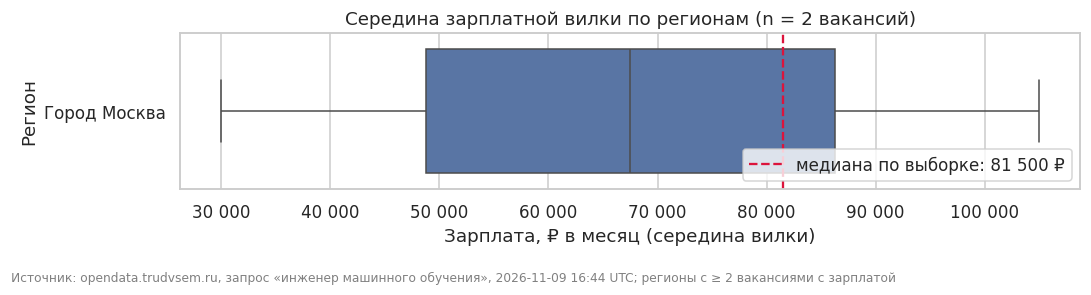

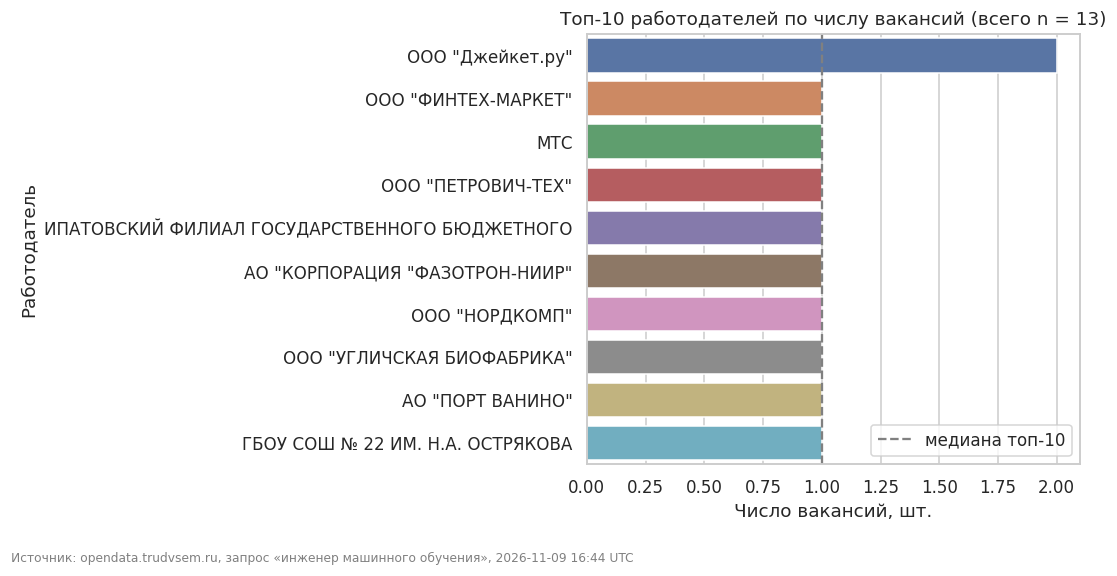

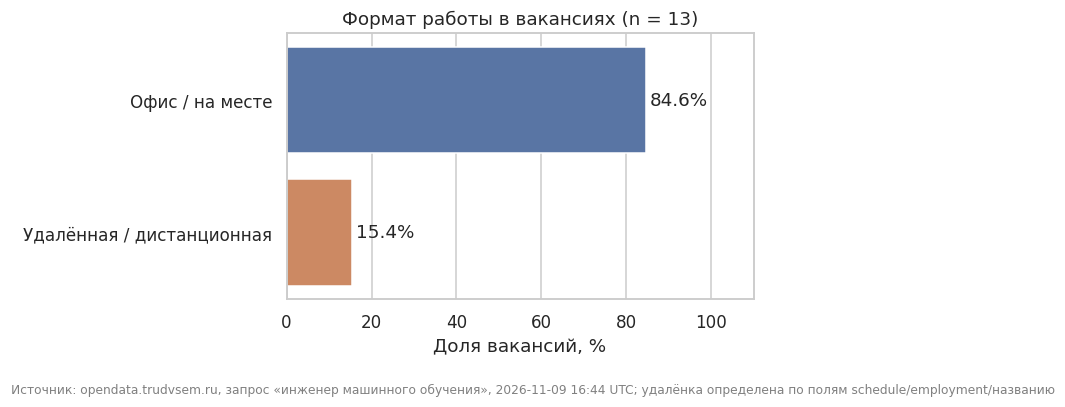

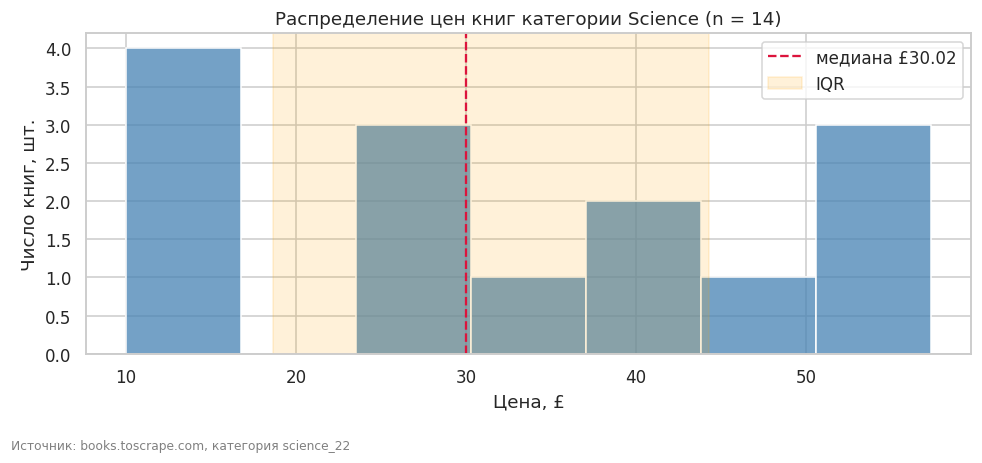

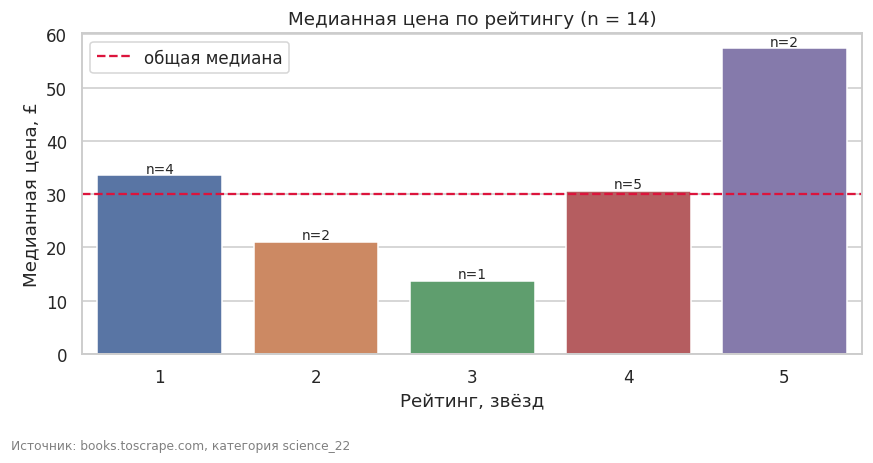

In [6]:
#@title Шаг 5. Разведочный анализ и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 5.1
# Вариант 1: медиана и IQR зарплатной вилки по регионам; топ-10 работодателей;
# доля удалённых вакансий; гистограмма цен каталога (+ цена по рейтингу как доп. график).
TOP_REGIONS = 10        # сколько регионов показываем на графике зарплат
MIN_VAC_IN_REGION = 2   # регион с одной вакансией не даёт осмысленной медианы/IQR
SRC_API = f"Источник: opendata.trudvsem.ru, запрос «{CFG['api_params']['text']}», {COLLECTED_AT}"
SRC_WEB = f"Источник: books.toscrape.com, категория {CFG['site_params']['category']}"


def footnote(fig, text):
    fig.text(0.01, -0.02, text, fontsize=8, color="gray", ha="left", va="top")


# --- 5.1. Зарплатная вилка по регионам: таблица медиан и IQR + boxplot --------------------
sal = df_api.dropna(subset=["salary_mid", "region"]) if not df_api.empty else pd.DataFrame()
if len(sal):
    by_region = (sal.groupby("region")["salary_mid"]
                 .agg(n="size", median="median",
                      q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75))
                 .assign(IQR=lambda d: d.q3 - d.q1)
                 .query("n >= @MIN_VAC_IN_REGION")
                 .sort_values(["n", "median"], ascending=False).head(TOP_REGIONS))
    display(by_region.round(0))
    plot_df = sal[sal["region"].isin(by_region.index)]
    order = by_region.sort_values("median", ascending=False).index
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(order) + 2))
    sns.boxplot(data=plot_df, y="region", x="salary_mid", order=order, hue="region",
                legend=False, ax=ax, showfliers=True)
    overall = sal["salary_mid"].median()
    ax.axvline(overall, ls="--", color="crimson", label=f"медиана по выборке: {overall:,.0f} ₽".replace(",", " "))
    ax.set(title=f"Середина зарплатной вилки по регионам (n = {len(plot_df)} вакансий)",
           xlabel="Зарплата, ₽ в месяц (середина вилки)", ylabel="Регион")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
    ax.legend(loc="lower right")
    footnote(fig, SRC_API + f"; регионы с ≥ {MIN_VAC_IN_REGION} вакансиями с зарплатой")
    plt.tight_layout(); plt.show()
else:
    print("Нет вакансий с указанной зарплатой — график по регионам не строится")

# --- 5.2. Топ-10 работодателей --------------------------------------------------------
if not df_api.empty and df_api["employer"].notna().any():
    top_emp = df_api["employer"].value_counts().head(10).rename_axis("employer").reset_index(name="n")
    top_emp["employer_short"] = top_emp["employer"].str.slice(0, 45)
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=top_emp, y="employer_short", x="n", hue="employer_short", legend=False, ax=ax)
    ax.axvline(top_emp["n"].median(), ls="--", color="gray", label="медиана топ-10")
    ax.set(title=f"Топ-10 работодателей по числу вакансий (всего n = {len(df_api)})",
           xlabel="Число вакансий, шт.", ylabel="Работодатель")
    ax.legend(loc="lower right")
    footnote(fig, SRC_API)
    plt.tight_layout(); plt.show()

# --- 5.3. Доля удалённых вакансий -----------------------------------------------------
if not df_api.empty:
    remote = (df_api["is_remote"].map({True: "Удалённая / дистанционная", False: "Офис / на месте"})
              .value_counts(normalize=True).mul(100).rename_axis("format").reset_index(name="pct"))
    fig, ax = plt.subplots(figsize=(7, 3.5))
    sns.barplot(data=remote, y="format", x="pct", hue="format", legend=False, ax=ax)
    for i, v in enumerate(remote["pct"]):
        ax.text(v + 1, i, f"{v:.1f}%", va="center")
    ax.set(title=f"Формат работы в вакансиях (n = {len(df_api)})",
           xlabel="Доля вакансий, %", ylabel="", xlim=(0, 110))
    footnote(fig, SRC_API + "; удалёнка определена по полям schedule/employment/названию")
    plt.tight_layout(); plt.show()

# --- 5.4. Гистограмма цен каталога ----------------------------------------------------
prices = df_web["price"].dropna() if "price" in df_web else pd.Series(dtype=float)
if len(prices):
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(prices, bins=min(15, max(5, len(prices) // 2)), ax=ax, color="steelblue")
    ax.axvline(prices.median(), color="crimson", ls="--", label=f"медиана £{prices.median():.2f}")
    ax.axvspan(prices.quantile(.25), prices.quantile(.75), color="orange", alpha=.15, label="IQR")
    ax.set(title=f"Распределение цен книг категории Science (n = {len(prices)})",
           xlabel="Цена, £", ylabel="Число книг, шт.")
    ax.legend()
    footnote(fig, SRC_WEB)
    plt.tight_layout(); plt.show()

# --- 5.5 (дополнительно). Цена по рейтингу --------------------------------------------
if "rating" in df_web and df_web["rating"].notna().any():
    by_rating = df_web.groupby("rating", observed=True)["price"].agg(["size", "median"]).reset_index()
    by_rating["rating"] = by_rating["rating"].astype(int).astype(str)
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=by_rating, x="rating", y="median", hue="rating", legend=False, ax=ax)
    for i, r in by_rating.iterrows():
        ax.text(i, r["median"] + .5, f"n={r['size']}", ha="center", fontsize=9)
    ax.axhline(prices.median(), ls="--", color="crimson", label="общая медиана")
    ax.set(title=f"Медианная цена по рейтингу (n = {len(df_web)})",
           xlabel="Рейтинг, звёзд", ylabel="Медианная цена, £")
    ax.legend()
    footnote(fig, SRC_WEB)
    plt.tight_layout(); plt.show()


**Как читать вывод.** Анализируйте те показатели, которые перечислены в `CFG["metrics"]` для **вашего** варианта. Для цен и зарплат уместны распределения, медианы и квартили; для репозиториев — звёзды и форки; для валют — динамика и волатильность; для погоды — временные ряды и рисковые дни; для публикаций — годы, цитируемость и организации. На каждом графике указывайте источник, число наблюдений (`n`), единицы измерения и ограничения выборки. Не переносите метрики из других вариантов и не создавайте отсутствующие в источнике признаки.


### Шаг 6. Выводы и управленческие рекомендации

**Зачем мы это делаем.** Заказчику нужны не графики, а решения: входить ли в нишу, по какой цене, хватит ли на рынке специалистов. Метрики считаем кодом, а в текст переносим уже посчитанные значения — так вывод невозможно «придумать».

In [7]:
#@title Шаг 6. Метрики для выводов: считаем, а не придумываем { display-mode: "form" }
def safe(series, func, default=float("nan")):
    """Вычислить показатель для существующего числового поля."""
    s = pd.to_numeric(series, errors="coerce").dropna() if series is not None else pd.Series(dtype=float)
    return func(s) if len(s) else default

metrics = {
    "Вариант": CFG["id"],
    "Записей API": len(df_api),
    "HTML-объектов": len(df_web),
}
# Добавляем только показатели, чьи столбцы реально существуют после очистки.
if "price" in df_web:
    metrics["Медианная цена"] = safe(df_web["price"], lambda s: round(s.median(), 2))
    metrics["Разброс цен (IQR)"] = safe(
        df_web["price"], lambda s: round(s.quantile(.75) - s.quantile(.25), 2))
if "stock" in df_web:
    stock_values = pd.to_numeric(df_web["stock"], errors="coerce")
    metrics["Доля позиций в наличии"] = round(float(stock_values.dropna().gt(0).mean()), 3) if stock_values.notna().any() else float("nan")
if "rating" in df_web:
    metrics["Средний рейтинг"] = safe(df_web["rating"], lambda s: round(s.mean(), 2))
if CFG["api"] == "trudvsem" and "salary_mid" in df_api:
    metrics["Медиана зарплатной вилки"] = safe(df_api["salary_mid"], lambda s: round(s.median(), 2))
    metrics["Доля вакансий с зарплатой"] = round(float(df_api["salary_mid"].notna().mean()), 3) if len(df_api) else float("nan")
if CFG["api"] == "trudvsem" and "is_remote" in df_api:
    metrics["Доля удалённых вакансий"] = safe(df_api["is_remote"], lambda s: round(s.astype(float).mean(), 3))

summary = pd.Series(metrics, name="значение").to_frame()
display(summary)

print(f"Источники: API — {API_SOURCE}; сайт — {WEB_SOURCE}. "
      f"Запросов в журнале: {len(REQUEST_LOG)}, с ошибкой: "
      f"{sum(1 for m in REQUEST_LOG if m.get('error'))}.")
print("Проверьте также специфические показатели и минимум четыре графика своего варианта (CFG['metrics']).")
if API_SOURCE in ("synthetic", "offline-snapshot") or WEB_SOURCE in ("synthetic", "offline-snapshot"):
    print("⚠ Есть аварийные данные: пометьте их в отчёте и не выдавайте за реальные рыночные наблюдения.")


,значение
Вариант,1.000
Записей API,13.000
HTML-объектов,14.000
Медианная цена,30.020
Разброс цен (IQR),25.630
Доля позиций в наличии,1.000
Средний рейтинг,2.930
Медиана зарплатной вилки,81500.000
Доля вакансий с зарплатой,1.000
Доля удалённых вакансий,0.154


Источники: API — trudvsem; сайт — books. Запросов в журнале: 17, с ошибкой: 1.
Проверьте также специфические показатели и минимум четыре графика своего варианта (CFG['metrics']).


In [14]:
#@title Шаг 6.1. Черновик выводов из посчитанных чисел { display-mode: "form" }
# Текст собирается из реальных метрик, чтобы в выводах не было «придуманных» чисел.
# Перенесите его в markdown-ячейку ниже и дополните своей интерпретацией.
def fmt(x, unit=""):
    return "н/д" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:,.0f}{unit}".replace(",", " ")

n_api, n_web = len(df_api), len(df_web)
sal_share = df_api["salary_mid"].notna().mean() if n_api else float("nan")
med_sal = df_api["salary_mid"].median() if n_api else float("nan")
remote_share = df_api["is_remote"].mean() if n_api else float("nan")
lines = [f"1. Собрано: {n_api} уникальных вакансий (trudvsem, «{CFG['api_params']['text']}») и "
         f"{n_web} книг (books.toscrape, {CFG['site_params']['category']}); дата сбора {COLLECTED_AT}."]
if n_api:
    top_reg = df_api["region"].value_counts().head(3)
    lines.append(f"2. Зарплата указана в {sal_share:.0%} вакансий, медиана середины вилки — {fmt(med_sal, ' ₽')}.")
    if 'by_region' in globals() and len(by_region) >= 2:
        hi, lo = by_region["median"].idxmax(), by_region["median"].idxmin()
        lines.append(f"   Самая высокая медиана — {hi} ({fmt(by_region.loc[hi, 'median'], ' ₽')}), "
                     f"самая низкая — {lo} ({fmt(by_region.loc[lo, 'median'], ' ₽')}).")
    elif 'by_region' in globals() and len(by_region) == 1:
        only = by_region.index[0]
        lines.append(f"   Сравнить регионы нельзя: ≥ {MIN_VAC_IN_REGION} вакансий с зарплатой есть только "
                     f"в регионе {only} (n = {by_region.loc[only, 'n']}, медиана "
                     f"{fmt(by_region.loc[only, 'median'], ' ₽')}); в остальных — по одной или без зарплаты.")
    lines.append("   Больше всего вакансий: " + "; ".join(f"{r} — {c}" for r, c in top_reg.items()) + ".")
    lines.append(f"   Доля удалённых вакансий — {remote_share:.1%}.")
    emp = df_api["employer"].value_counts()
    if len(emp):
        lines.append(f"   Топ-10 работодателей дают {emp.head(10).sum() / n_api:.0%} всех вакансий; лидер — {emp.index[0]} ({emp.iloc[0]}).")
if n_web:
    p = df_web["price"]
    lines.append(f"3. Каталог: медиана £{p.median():.2f}, IQR £{p.quantile(.75) - p.quantile(.25):.2f}, "
                 f"средний рейтинг {df_web['rating'].astype(float).mean():.2f}, "
                 f"в наличии {df_web['in_stock'].mean():.0%} позиций.")
print("\n".join(lines))


1. Собрано: 13 уникальных вакансий (trudvsem, «инженер машинного обучения») и 14 книг (books.toscrape, science_22); дата сбора 2026-11-09 16:44 UTC.
2. Зарплата указана в 100% вакансий, медиана середины вилки — 81 500 ₽.
   Сравнить регионы нельзя: ≥ 2 вакансий с зарплатой есть только в регионе Город Москва (n = 2, медиана 67 500 ₽); в остальных — по одной или без зарплаты.
   Больше всего вакансий: Город Москва — 2; Самарская область — 1; Город Санкт-Петербург — 1.
   Доля удалённых вакансий — 15.4%.
   Топ-10 работодателей дают 85% всех вакансий; лидер — ООО "Джейкет.ру" (2).
3. Каталог: медиана £30.02, IQR £25.63, средний рейтинг 2.93, в наличии 100% позиций.


**Как читать вывод.** Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

### Выводы и рекомендации (вариант 1 — HR-аналитика, рынок AI/ML-инженеров)

**1. Что собрано.**
* **API «Работа в России»** (opendata.trudvsem.ru, данные Роструда, без ключа), запрос «инженер машинного обучения», до 5 страниц по 100 записей. Получено **13 уникальных вакансий** — это все вакансии, доступные по запросу: первая страница оказалась неполной, и пагинация остановилась. Дата сбора — **09.11.2026, 16:44 UTC**.
* **HTML-витрина books.toscrape.com**, категория Science (`science_22`): **14 книг** — вся категория. Она состоит из одной страницы, запрос второй страницы вернул 404.
* Парсинг выполнен двумя способами (BeautifulSoup и XPath), результаты совпали полностью (14 из 14). Сбор шёл с паузой 0,5 с, повторами при 429/5xx и кэшем ответов.
* Ориентиры по объёму (50 записей API / 40 HTML-объектов) не достигнуты по объективной причине: источники содержат меньше данных. Дублирования и подмены источника не было.

**2. Что показывают данные.**
* **Предложение крайне мало:** на федеральном портале по запросу всего 13 вакансий AI/ML-инженеров на всю страну. Для этой специальности портал не является основным каналом найма.
* **Уровень оплаты:** зарплата указана во всех 13 вакансиях (100 %), медиана середины вилки — **81 500 ₽/мес**.
* **География:** больше одной вакансии только в Москве (2 вакансии, медиана 67 500 ₽). В остальных регионах (Самарская область, Санкт-Петербург и др.) по одной вакансии, поэтому сравнить зарплаты по регионам статистически нельзя.
* **Работодатели:** рынок раздроблен. Лидер, ООО «Джейкет.ру», разместил всего 2 вакансии; топ-10 работодателей дают 85 % вакансий, то есть почти каждая вакансия приходится на отдельную компанию.
* **Формат работы:** удалённую работу предлагают **15,4 %** вакансий (2 из 13).
* **Каталог (учебный, к рынку труда не относится):** медианная цена книги £30,02, IQR £25,63, средний рейтинг 2,93 из 5, в наличии 100 % позиций.

**3. Управленческие рекомендации.**
1. **Не использовать «Работу в России» как основной источник для оценки рынка ML-инженеров.** Основание: 13 вакансий по всей России. Ожидаемый эффект: решения по найму и бюджету не будут опираться на нерепрезентативную выборку. Как проверить: собрать вакансии из профильных источников (Хабр Карьера, SuperJob, hh.ru по API для работодателей) и сравнить объём и медиану.
2. **Предлагать кандидатам удалённый формат.** Основание: его дают только 15,4 % работодателей в выборке, это редкое преимущество. Ожидаемый эффект: больше откликов, в том числе из регионов. Как проверить: A/B-тест — одна вакансия в офисном и удалённом вариантах, сравнить число откликов за 2–4 недели.
3. **Не использовать 81 500 ₽ как ориентир для оффера без дополнительной проверки.** Основание: медиана посчитана по 13 вакансиям госпортала, где коммерческий IT-сектор представлен слабо, поэтому значение, вероятно, занижено. Ожидаемый эффект: меньше отказов кандидатов от оффера. Как проверить: сравнить с медианой по профильным источникам и отраслевым обзорам зарплат.

**4. Ограничения и риски.**
* Очень маленькие выборки (13 вакансий, 14 книг): медианы и доли неустойчивы, одна вакансия меняет долю на ~7,7 п. п.
* Смещение источника: портал отражает в основном госсектор и крупный бизнес; hh.ru с 2026 года закрыт для неавторизованных запросов.
* Поиск по тексту может захватывать смежные вакансии, а часть ML-вакансий называется иначе («data scientist», «ML engineer»).
* Удалённая работа определялась по полям графика, занятости и названию вакансии — возможна недооценка.
* Это единичный срез на 09.11.2026, динамики нет.
* Витрина books.toscrape.com — учебная, выводы по ней не переносятся на реальный рынок.

**5. Что делать дальше.**
* Повторять сбор еженедельно и накапливать снимки, чтобы видеть динамику.
* Расширить запрос синонимами («data scientist», «ML-инженер», «машинное обучение») с дедупликацией, но анализировать отдельно от исходного запроса варианта.
* Добавить профильные источники вакансий для проверки уровня зарплат.
* Сравнивать регионы только после того, как в каждом наберётся хотя бы 5–10 вакансий с зарплатой.

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель. Параметры подставляются в код автоматически по значению `VARIANT` из шага 1. Вариант 30 разобран в версии для преподавателя как эталон.

**Ориентир объёма:** не менее **50 уникальных записей из API** и **40 HTML-объектов**. Если выбранный источник или параметры варианта объективно дают меньше, соберите все доступные уникальные записи и обоснуйте ограничение. Не дублируйте записи ради порога и не меняйте назначенный вариант без согласования. Для Open-Meteo объём может зависеть от числа городов и дней прогноза, для сайтов с тегами — от числа доступных карточек.

| № | Сфера | Бизнес-задача | Источник API | Сайт для парсинга | Параметры сбора | Целевые метрики и визуализации |
|---:|---|---|---|---|---|---|
| 1 | HR-аналитика | Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят | opendata.trudvsem.ru | books.toscrape.com | API: text=инженер машинного обучения, pages=5, per_page=100<br>Сайт: category=science_22, pages=3 | Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога |
| 2 | E-commerce | Ценовое позиционирование в нише деловой литературы | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик маркетплейсов, pages=4, per_page=100<br>Сайт: category=business_35, pages=3 | Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат |
| 3 | Финтех | Валютный риск закупок: динамика USD и EUR за квартал | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=90<br>Сайт: category=travel_2, pages=2 | Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли |
| 4 | Мониторинг конкурентов | Сравнение ассортимента двух товарных категорий | api.github.com | books.toscrape.com | API: q=price monitoring, sort=stars, pages=2, per_page=50<br>Сайт: category=fiction_10, pages=4 | Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки» |
| 5 | Наука и инновации | Научная активность в сфере FinTech: динамика публикаций | api.openalex.org | quotes.toscrape.com | API: search=fintech, from_year=2019, per_page=100, pages=2<br>Сайт: tag=inspirational, pages=4 | Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов |
| 6 | Логистика | Погодные риски на складских хабах: планирование окон отгрузки | api.open-meteo.com | books.toscrape.com | API: cities=['Москва', 'Екатеринбург', 'Новосибирск'], days=14<br>Сайт: category=history_32, pages=2 | Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога |
| 7 | HR-аналитика | Спрос на дата-инженеров и требования к стеку | opendata.trudvsem.ru | quotes.toscrape.com | API: text=инженер данных, pages=5, per_page=100<br>Сайт: tag=life, pages=3 | Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат |
| 8 | E-commerce | Влияние рейтинга на цену: есть ли премия за качество | api.github.com | books.toscrape.com | API: q=recommender system, sort=stars, pages=2, per_page=50<br>Сайт: category=romance_8, pages=4 | Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев |
| 9 | Финтех | Стоимость валютной корзины импортёра | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['USD', 'EUR', 'CNY'], days=120<br>Сайт: section=computers/laptops, pages=3 | Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу |
| 10 | Мониторинг конкурентов | Глубина ассортимента и «дыры» в наличии у конкурента | opendata.trudvsem.ru | books.toscrape.com | API: text=категорийный менеджер, pages=4, per_page=100<br>Сайт: category=mystery_3, pages=4 | Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям |
| 11 | Наука и инновации | Публикационный ландшафт по теме «supply chain analytics» | api.openalex.org | scrapethissite.com/pages | API: search=supply chain analytics, from_year=2020, per_page=100, pages=2<br>Сайт: section=countries, pages=1 | Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран |
| 12 | Логистика | Температурный режим перевозок: risk-календарь на две недели | api.open-meteo.com | webscraper.io/test-sites/e-commerce/allinone | API: cities=['Санкт-Петербург', 'Казань', 'Краснодар'], days=14<br>Сайт: section=computers/tablets, pages=3 | Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов |
| 13 | HR-аналитика | BI-аналитики: сколько стоит и что требуют работодатели | opendata.trudvsem.ru | books.toscrape.com | API: text=BI аналитик, pages=5, per_page=100<br>Сайт: category=business_35, pages=3 | Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости |
| 14 | Технологические тренды | Экосистема инструментов парсинга: кто лидирует | api.github.com | quotes.toscrape.com | API: q=web scraping, sort=stars, pages=2, per_page=50<br>Сайт: tag=books, pages=3 | Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды |
| 15 | E-commerce | Ценовые сегменты в детской нише: где «дыра» в предложении | opendata.trudvsem.ru | books.toscrape.com | API: text=менеджер интернет-магазина, pages=4, per_page=100<br>Сайт: category=childrens_11, pages=4 | Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей |
| 16 | Финтех | Курс юаня и импорт электроники: чувствительность цены | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['CNY'], days=180<br>Сайт: section=phones/touch, pages=2 | Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса |
| 17 | Наука и инновации | Исследования по «digital twin» в промышленности | api.openalex.org | books.toscrape.com | API: search=digital twin manufacturing, from_year=2018, per_page=100, pages=2<br>Сайт: category=science_22, pages=3 | Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости |
| 18 | Мониторинг конкурентов | Сравнение цен и «звёздности» ассортимента двух категорий | api.github.com | books.toscrape.com | API: q=e-commerce analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=food-and-drink_33, pages=3 | Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики |
| 19 | HR-аналитика | Логистические профессии: дефицит кадров по регионам | opendata.trudvsem.ru | scrapethissite.com/pages | API: text=логист, pages=6, per_page=100<br>Сайт: section=countries, pages=1 | Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн) |
| 20 | Логистика | Окна доставки в северных хабах на горизонте 16 дней | api.open-meteo.com | books.toscrape.com | API: cities=['Мурманск', 'Архангельск', 'Якутск'], days=16<br>Сайт: category=travel_2, pages=2 | Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза |
| 21 | E-commerce | Автоматизация мониторинга: как часто меняется наличие товара | api.github.com | books.toscrape.com | API: q=price tracker, sort=stars, pages=2, per_page=50<br>Сайт: category=sequential-art_5, pages=4 | Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен |
| 22 | Финтех | Волатильность рубля как фактор ценообразования | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=365<br>Сайт: category=business_35, pages=3 | Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 % |
| 23 | HR-аналитика | Продуктовые аналитики: требования и вилки | opendata.trudvsem.ru | quotes.toscrape.com | API: text=продуктовый аналитик, pages=5, per_page=100<br>Сайт: tag=humor, pages=3 | Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты |
| 24 | Технологические тренды | Инструменты работы с данными: Python-экосистема | api.github.com | webscraper.io/test-sites/e-commerce/allinone | API: q=pandas alternative dataframe, sort=stars, pages=2, per_page=50<br>Сайт: section=computers/laptops, pages=3 | Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx) |
| 25 | Наука и инновации | Публикации по «marketplace pricing»: кто задаёт повестку | api.openalex.org | books.toscrape.com | API: search=marketplace pricing, from_year=2019, per_page=100, pages=2<br>Сайт: category=business_35, pages=3 | Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога |
| 26 | Логистика | Планирование складских смен по погодным окнам | api.open-meteo.com | scrapethissite.com/pages | API: cities=['Ростов-на-Дону', 'Самара', 'Пермь'], days=14<br>Сайт: section=hockey, pages=2 | Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией |
| 27 | Мониторинг конкурентов | Бенчмарк цен на технику: разброс внутри линейки | opendata.trudvsem.ru | webscraper.io/test-sites/e-commerce/allinone | API: text=менеджер по закупкам, pages=4, per_page=100<br>Сайт: section=computers/laptops, pages=3 | Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков |
| 28 | E-commerce | Влияние глубины каталога на средний чек (гипотеза) | api.github.com | books.toscrape.com | API: q=shopping cart analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=poetry_23, pages=4 | Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев |
| 29 | Финтех | Кросс-курсы и арбитраж: USD, EUR, CNY за полгода | cbr.ru | quotes.toscrape.com | API: currencies=['USD', 'EUR', 'CNY'], days=180<br>Сайт: tag=life, pages=3 | Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат |
| 30 | E-commerce + HR (эталон преподавателя) | Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик данных, pages=3, per_page=100<br>Сайт: category=business_35, pages=3 | Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков |

## Критерии оценивания — максимум 10 баллов

Четыре блока по 25 из 100 условных единиц исходной рубрики соответствуют **четырём блокам по 2,5 балла** в Moodle. Оценку выставляет преподаватель по фактическому выполнению применимых требований, а не по одному числу автоматических проверок.

| Блок | Что оценивается | Максимум |
|---|---|---:|
| 1. Сбор данных | Корректная пагинация и остановка; паузы, повторные попытки, обработка HTTP-ответов и исключений; полнота **доступной уникальной** выборки, журнал сбора и объяснение объективных ограничений объёма | **2,5** |
| 2. Очистка, RegEx и XPath | Работающие CSS-селекторы и XPath со сверкой; обязательные общие RegEx-функции и тесты; распознавание ≥ 80% **применимых** значений; корректные типы столбцов `DataFrame` | **2,5** |
| 3. EDA и визуализация | Не менее четырёх содержательных графиков **по своему варианту**; названия, подписи осей, единицы измерения и объём выборки; подходящие метрики, читаемость | **2,5** |
| 4. Бизнес-выводы | Выводы с опорой на рассчитанные значения; конкретные действия, ожидаемый эффект и способ проверки; корректно указанные ограничения | **2,5** |
| **Итого** | | **10** |

### Шкала оценивания

| Баллы | Оценка |
|---|---|
| От 8 до 10 включительно | Отлично |
| От 7 до менее 8 | Хорошо |
| От 5 до менее 7 | Удовлетворительно |
| Менее 5 | Возврат на доработку |

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Ключ, токен или пароль в коде либо выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок | −1,0 |
| Выводы по аварийным или синтетическим данным без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо HTML-парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Вместо ссылки сдан файл либо ноутбук размещён без выводов ячеек | −1,0 |

**Неприменимые предметные проверки не снижают оценку.** Общие учебные RegEx-функции и их тесты, работа с API, HTML, EDA и выводы обязательны для всех вариантов. Если источник объективно меньше ориентира по объёму, обоснуйте это: преподаватель оценивает полноту доступных данных.

**Задание со звёздочкой:** можно получить **до +1,0 балла**, но **общий максимум по ПР1 — 10 баллов**. Дополнительный балл учитывается только при наличии выполненной основной работы; итог считается как `min(10; max(0; основные баллы − штрафы + бонус))`. Бонус не компенсирует отсутствие обязательных разделов.


In [11]:
#@title Самопроверка перед сдачей: с учётом вашего варианта { display-mode: "form" }
# Заполните только если источник объективно не позволяет достичь объёма выборки.
# Пустое или формальное объяснение НЕ освобождает от требования.
API_LIMIT_REASON = "По запросу «инженер машинного обучения» API «Работа в России» вернул все доступные вакансии: meta.total = 13 на дату сбора. Пагинация остановлена на первой неполной странице. Узкая специальность, портал охватывает в основном госсектор и крупный бизнес; hh.ru закрыт для неавторизованных запросов."  #@param {type:"string"}
HTML_LIMIT_REASON = "Категория Science (science_22) на books.toscrape.com содержит одну страницу: собраны все доступные книги, стр. 2 отвечает 404"  #@param {type:"string"}

checks = []

def check(name, passed=False, hint="", applicable=True, needs_review=False):
    """Статус проверки: PASS / FAIL / NA / REVIEW."""
    if not applicable:
        status = "NA"
    elif needs_review:
        status = "REVIEW"
    else:
        status = "PASS" if bool(passed) else "FAIL"
    checks.append((name, status, hint))

def unique_rows(frame):
    """Подсчитываем уникальные записи по всем полям, включая вложенные значения."""
    if frame.empty:
        return 0
    fingerprints = frame.apply(
        lambda row: json.dumps(row.to_dict(), sort_keys=True, ensure_ascii=False, default=str),
        axis=1)
    return fingerprints.nunique()

def check_volume(name, actual, expected, explanation):
    """Отклонение по объёму не засчитывается автоматически без проверки преподавателя."""
    if actual >= expected:
        check(f"{name}: {actual} / ориентир {expected}", True)
    elif explanation.strip():
        check(f"{name}: {actual} / ориентир {expected}",
              hint="⚠ Укажите в выводах и обоснуйте преподавателю: " + explanation.strip(),
              needs_review=True)
    else:
        check(f"{name}: {actual} / ориентир {expected}", False,
              "Соберите все доступные уникальные записи либо укажите объективную причину ограничения")

api_data = globals().get("df_api", pd.DataFrame())
web_data = globals().get("df_web", pd.DataFrame())
api_kind = CFG["api"]
site_kind = CFG["site"]
selected_metrics = CFG["metrics"].lower()

check("Выбран назначенный преподавателем вариант 1–30",
      isinstance(VARIANT, int) and 1 <= VARIANT <= 30 and CFG["id"] == VARIANT,
      "Проверьте, что выбран именно ваш вариант, а не значение по умолчанию")
check_volume("Записи API (уникальные, без искусственного дублирования)",
             unique_rows(api_data), 50, API_LIMIT_REASON)
check_volume("HTML-объекты (уникальные)", unique_rows(web_data), 40, HTML_LIMIT_REASON)

# При одинаковом числе объектов их порядок и ключевые поля должны совпадать.
bs4_rows = globals().get("rows_bs4", [])
xpath_rows = globals().get("rows_xpath", [])
bs4_labels = [row.get("title") or row.get("text") for row in bs4_rows]
xpath_labels = [row.get("title") or row.get("text") for row in xpath_rows]
check("BeautifulSoup и XPath: совпадают число объектов и названия/текст",
      bool(bs4_labels) and len(bs4_labels) == len(xpath_labels) and
      all(a == b for a, b in zip(bs4_labels, xpath_labels)),
      "Сравните CSS и XPath по составу, количеству и значениям; без совпадения нельзя считать парсинг проверенным")

# Числовые признаки могут находиться либо в API, либо в HTML-источнике.
has_numeric = any(
    pd.api.types.is_numeric_dtype(frame[col])
    for frame in (api_data, web_data) for col in frame.columns
)
check("Подготовлены типизированные числовые показатели для анализа", has_numeric,
      "Приведите необходимые поля своего варианта к числовым типам")

# Цены имеют смысл для товарных витрин, но НЕ для цитат / справочников / научных публикаций.
price_applicable = site_kind in ("books", "webscraper")
price_present = "price" in web_data.columns
price_share = (pd.to_numeric(web_data["price"], errors="coerce").notna().mean()
               if len(web_data) and price_present else 0)
check("Распознано ≥ 80% применимых цен HTML-витрины", price_share >= 0.80,
      "Проверьте очистку поля price и долю корректных значений", applicable=price_applicable)

# Требования к зарплатам и навыкам применяются лишь для соответствующих вакансий.
salary_applicable = api_kind == "trudvsem" and bool(
    re.search(r"зарплат|вилк|стоимость кадров|опыту", selected_metrics + " " + CFG["task"].lower()))
skills_applicable = api_kind == "trudvsem" and bool(
    re.search(r"навык|технолог|требовани|стек", selected_metrics + " " + CFG["task"].lower()))
check("Обработано поле зарплаты вакансий", "salary_mid" in api_data.columns,
      "Для применимого варианта подготовьте столбец salary_mid, отсутствие зарплаты у вакансии отмечайте как NaN",
      applicable=salary_applicable)

skills_present = "skills" in api_data.columns and any(
    isinstance(value, (list, tuple, set)) and len(value) > 0
    or isinstance(value, str) and bool(value.strip())
    for value in api_data["skills"].dropna()
)
check("Извлечены навыки из текста требований вакансий", skills_present,
      "Если навыки предусмотрены заданием, примените extract_skills к реальному тексту требований",
      applicable=skills_applicable)

check("Выполнены тесты общих RegEx-функций", globals().get("REGEX_TESTS_OK", False),
      "Выполните шаг 4 целиком; общий набор тестов обязателен для всех вариантов")
check("Есть журнал запросов (паузы и повторы нужно проверить)",
      REQUEST_PAUSE >= 0.1 and bool(REQUEST_LOG),
      "Проверьте REQUEST_PAUSE, Retry-After и ограничения источника; одного журнала для доказательства корректности недостаточно")

secret_like = [key for key, value in list(globals().items())
               if isinstance(value, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", value)]
check("Не обнаружены типовые токены в строковых переменных", not secret_like,
      "Удалите обнаруженные секреты; отдельно проверьте весь код и выводы перед публикацией")
check("Не использованы аварийные или синтетические данные вместо реальных",
      API_SOURCE not in ("synthetic", "offline-snapshot") and
      WEB_SOURCE not in ("synthetic", "offline-snapshot"),
      "Если источник недоступен, обязательно отметьте это в выводах и не делайте рыночных утверждений")

marks = {"PASS": "✅", "FAIL": "❌", "NA": "➖", "REVIEW": "⚠"}
counts = {status: sum(item[1] == status for item in checks) for status in marks}
print(f"Вариант {CFG['id']} ({api_kind} / {site_kind})")
print(f"✅ Выполнено: {counts['PASS']} | ❌ Исправить: {counts['FAIL']} | "
      f"➖ Не применяется: {counts['NA']} | ⚠ Требует проверки: {counts['REVIEW']}\n")
for name, status, hint in checks:
    print(f"  {marks[status]} {name}" + (f" — {hint}" if status in ("FAIL", "REVIEW") and hint else ""))
print("\nСамопроверка — подсказка, а не автоматическое начисление или снятие баллов.")
print("Проверьте вручную: ≥ 4 графика, выводы, применимые метрики, отсутствие секретов и ссылку GitHub.")
if counts["REVIEW"]:
    print("⚠ Причины ограничения выборки должен оценить преподаватель: автоматического зачёта нет.")


Вариант 1 (trudvsem / books)
✅ Выполнено: 9 | ❌ Исправить: 0 | ➖ Не применяется: 1 | ⚠ Требует проверки: 2

  ✅ Выбран назначенный преподавателем вариант 1–30
  ⚠ Записи API (уникальные, без искусственного дублирования): 13 / ориентир 50 — ⚠ Укажите в выводах и обоснуйте преподавателю: По запросу «инженер машинного обучения» API «Работа в России» вернул все доступные вакансии: meta.total = 13 на дату сбора. Пагинация остановлена на первой неполной странице. Узкая специальность, портал охватывает в основном госсектор и крупный бизнес; hh.ru закрыт для неавторизованных запросов.
  ⚠ HTML-объекты (уникальные): 14 / ориентир 40 — ⚠ Укажите в выводах и обоснуйте преподавателю: Категория Science (science_22) на books.toscrape.com содержит одну страницу: собраны все доступные книги, стр. 2 отвечает 404
  ✅ BeautifulSoup и XPath: совпадают число объектов и названия/текст
  ✅ Подготовлены типизированные числовые показатели для анализа
  ✅ Распознано ≥ 80% применимых цен HTML-витрины
  ✅ Обработ

## Задание со звёздочкой (необязательное, до +1 балла при общем максимуме 10)

Разовый сбор данных — учебная задача. Производственная задача — **мониторинг**: данные собираются регулярно, источник меняется, и система должна оставаться устойчивой. Выберите **одно** из направлений ниже и покажите измеримый результат. Учитывайте свою предметную область: например, дедупликация вакансий подходит для HR, а мониторинг каталога — для e-commerce.

Бонус оценивается преподавателем только при выполнении основной части работы и не повышает итоговую оценку выше **10 баллов**. Он не заменяет обязательные этапы и не отменяет штрафы.


In [12]:
#@title Задание со звёздочкой — вариант E: устойчивость парсера { display-mode: "form" }
# Выберите одну задачу и решите её ниже. Каждая проверяется измеримым результатом.
#
# A. Условные запросы и инкрементальность.
#    Сохраните ETag/Last-Modified ответа, при повторном сборе отправьте заголовки
#    If-None-Match / If-Modified-Since и покажите, сколько запросов вернули 304 Not Modified
#    и сколько трафика это сэкономило.
#
# B. Параллельный сбор с соблюдением лимита.
#    Переведите обход пагинации на concurrent.futures.ThreadPoolExecutor с ограничителем
#    скорости (token bucket). Измерьте ускорение и докажите, что частота запросов
#    не превысила заданный порог.
#
# C. Дедупликация объявлений.
#    Одна вакансия часто публикуется несколько раз. Постройте дубликаты через шинглы
#    и коэффициент Жаккара, оцените долю дублей и покажите, как она искажает медиану зарплаты.
#
# D. Мониторинг вместо разового сбора.
#    Сохраните снимок в parquet с меткой времени, реализуйте второй запуск и таблицу
#    изменений (новые позиции, изменённые цены, исчезнувшие товары).
#
# E. Устойчивость парсера.
#    Напишите тесты, которые ломают парсер: отсутствующий тег, пустая цена, изменённый
#    класс. Добейтесь, чтобы парсер не падал, а помечал строку как проблемную.

# Ломаем разметку карточки и проверяем, что парсер не падает, а помечает строку как проблемную.
GOOD_CARD = """<article class="product_pod"><h3><a href="x/index.html" title="Book A">Book A</a></h3>
<p class="star-rating Four"></p><div class="product_price"><p class="price_color">£10.50</p>
<p class="instock availability"><i></i> In stock</p></div></article>"""
BROKEN = {
    "нет тега цены":        GOOD_CARD.replace('<p class="price_color">£10.50</p>', ""),
    "пустая цена":          GOOD_CARD.replace("£10.50", ""),
    "изменён класс цены":   GOOD_CARD.replace("price_color", "price-new"),
    "нет рейтинга":         GOOD_CARD.replace('<p class="star-rating Four"></p>', ""),
    "нет заголовка":        re.sub(r"<h3>.*?</h3>", "", GOOD_CARD, flags=re.S),
    "мусорный текст цены":  GOOD_CARD.replace("£10.50", "цена по запросу"),
}
REQUIRED = ("title", "price", "rating")

def robust_parse(html):
    """Разбор + очистка; вместо исключения — флаг problem и список отсутствующих полей."""
    try:
        rows = parse_with_bs4(f"<html><body>{html}</body></html>", "books")
    except Exception as e:                       # парсер не должен ронять пайплайн
        return [{"problem": True, "missing": [f"exception: {type(e).__name__}"]}]
    out = []
    for r in rows:
        r["price"] = parse_price(r.get("price_text"))
        r["rating"] = parse_rating(r.get("rating_class"))
        missing = [f for f in REQUIRED if r.get(f) is None]
        out.append({**r, "problem": bool(missing), "missing": missing})
    return out

results = [("исходная карточка", robust_parse(GOOD_CARD)[0])]
results += [(name, robust_parse(h)[0]) for name, h in BROKEN.items()]
report = pd.DataFrame([{"сценарий": n, "упал": False, "помечена проблемной": r["problem"],
                        "чего нет": ", ".join(r["missing"]) or "—"} for n, r in results])
display(report)
assert not report.loc[0, "помечена проблемной"], "исправная карточка не должна быть проблемной"
assert report.loc[1:, "помечена проблемной"].all(), "каждая поломка должна быть обнаружена"
print(f"Сценариев поломки: {len(BROKEN)} | парсер не упал ни разу | обнаружено поломок: "
      f"{int(report.loc[1:, 'помечена проблемной'].sum())} из {len(BROKEN)}")


,сценарий,упал,помечена проблемной,чего нет
0,исходная карточка,False,False,—
1,нет тега цены,False,True,price
2,пустая цена,False,True,price
3,изменён класс цены,False,True,price
4,нет рейтинга,False,True,rating
5,нет заголовка,False,True,title
6,мусорный текст цены,False,True,price


Сценариев поломки: 6 | парсер не упал ни разу | обнаружено поломок: 6 из 6
